### Импорты и параметры

In [11]:
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.model_selection import StratifiedGroupKFold

import solution_utils as su

TRAIN_PATH = os.environ.get("HW2_TRAIN", "hw1_train.jsonl")
FRAME_CACHE = "frame_all.pkl"
SEED = 42
N_JOBS = -1

MIN_CONF_GRID = [0.4, 0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.85, 0.99]
TOP_PER_CLASS = 150
MAX_ROUNDS = 40
MIN_NEW = 10

HIDDEN_PATH = os.environ.get("HW2_HIDDEN", "hidden_test.jsonl")
HIDDEN_LABELS = os.environ.get("HW2_HIDDEN_LABELS", "hidden_labels.jsonl")
os.makedirs("results", exist_ok=True)

### Данные и разбиение (как в HW1 и HW2)

In [12]:
if os.path.exists(FRAME_CACHE):
    frame_all = pd.read_pickle(FRAME_CACHE)
else:
    frame_all = su.to_frame(su.read_dialogs(TRAIN_PATH))
    frame_all.to_pickle(FRAME_CACHE)

df = frame_all[frame_all.reaction.notna()].reset_index(drop=True)
unlabeled = frame_all[frame_all.reaction.isna()].reset_index(drop=True)

outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(outer.split(df, df.reaction, df.group))
train, test = df.iloc[train_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
inner_cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED + 2)
outer_folds = list(outer_cv.split(train, train.reaction, train.group))

assert not set(train.dialog_id) & set(unlabeled.dialog_id) and not set(test.dialog_id) & set(unlabeled.dialog_id)
print(f"train: {len(train)}, test: {len(test)}, без метки (источник псевдо-разметки): {len(unlabeled)}")

train: 2400, test: 600, без метки (источник псевдо-разметки): 7000


## 1. Модели-разметчики: лучшая из HW1 и лучшая из HW2

In [13]:
reaction_models = su.init_reaction_models()
OLD = {n.removeprefix("hw1_"): m for n, m in reaction_models.items() if n.startswith("hw1_")}
NEW = {n.removeprefix("hw2_"): m for n, m in reaction_models.items() if n.startswith("hw2_") and "stack" not in n}
assert OLD, "в artifacts/reaction_models нет моделей HW1: скопируйте туда reaction_*.joblib из hw1/artifacts"
assert NEW, "в artifacts/reaction_models нет моделей HW2: выполните model_training.ipynb"


def cv_macro_f1(models):
    out = {}
    for name, model in models.items():
        oof = np.empty(len(train), dtype=object)
        for fit_idx, val_idx in outer_folds:
            oof[val_idx] = clone(model).fit(train.iloc[fit_idx], train.reaction.iloc[fit_idx]).predict(train.iloc[val_idx])
        out[name] = su.reaction_metrics(train.reaction, oof)["macro_f1"]
    return out


old_scores, new_scores = cv_macro_f1(OLD), cv_macro_f1(NEW)
best_old, best_new = max(old_scores, key=old_scores.get), max(new_scores, key=new_scores.get)
print("HW1:", {n: round(v, 3) for n, v in old_scores.items()})
print("HW2:", {n: round(v, 3) for n, v in new_scores.items()})
LABELERS = {"hw1": (best_old, OLD[best_old]), "hw2": (best_new, NEW[best_new])}
print({k: v[0] for k, v in LABELERS.items()})

HW1: {'dummy_most_frequent': 0.248, 'linear_svm': 0.577, 'linear_svm_my': 0.614, 'logreg': 0.579, 'logreg_my': 0.634, 'nb': 0.479, 'nb_my': 0.585}
HW2: {'gb_lsa': 0.638, 'hgb_lsa': 0.634, 'rf_lsa': 0.633, 'rf_tfidf': 0.63}
{'hw1': 'logreg_my', 'hw2': 'gb_lsa'}


In [14]:
def fit_labeler(labeled, base):
    """Переобучить разметчик (конвейер модели base с её параметрами) на labeled."""
    model = clone(base)
    if hasattr(model, "predict_proba"):
        return model.fit(labeled, labeled.reaction)
    splits = list(inner_cv.split(labeled, labeled.reaction, labeled.group))
    return CalibratedClassifierCV(model, cv=splits, method="sigmoid").fit(labeled, labeled.reaction)

### Распределение уверенности


hw1 logreg_my {0.4: 0.963, 0.5: 0.764, 0.6: 0.521, 0.7: 0.269, 0.8: 0.096, 0.85: 0.053, 0.9: 0.027, 0.99: 0.001}
hw2 gb_lsa {0.4: 0.993, 0.5: 0.923, 0.6: 0.769, 0.7: 0.591, 0.8: 0.365, 0.85: 0.224, 0.9: 0.091, 0.99: 0.001}


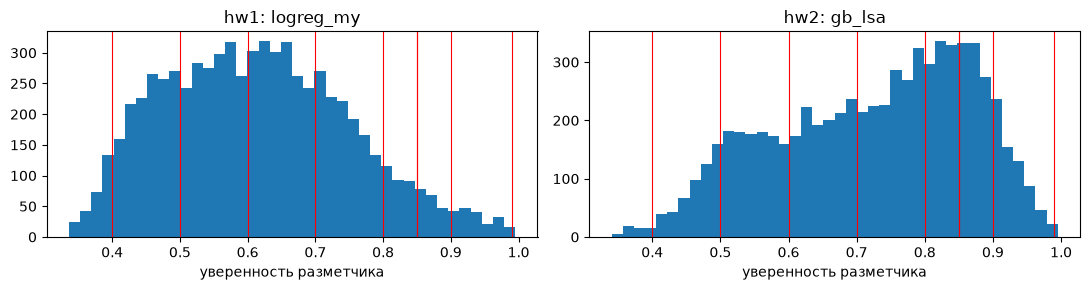

In [15]:
model0 = {k: fit_labeler(train, base) for k, (_, base) in LABELERS.items()}
fig, axes = plt.subplots(1, len(LABELERS), figsize=(5.5 * len(LABELERS), 3), squeeze=False)
for ax, (k, (name, _)) in zip(axes[0], LABELERS.items()):
    conf0 = model0[k].predict_proba(unlabeled).max(axis=1)
    print(k, name, {t: round(float((conf0 >= t).mean()), 3) for t in MIN_CONF_GRID})
    ax.hist(conf0, bins=40); ax.set_title(f"{k}: {name}")
    for t in MIN_CONF_GRID: ax.axvline(t, color="r", lw=.8)
    ax.set_xlabel("уверенность разметчика")
plt.tight_layout(); plt.show()

## 2. Итеративное дообучение

Каждый раунд: предсказать пул → выбрать по `TOP_PER_CLASS` самых уверенных ответов на класс (не ниже `min_conf`) → сохранить как разметку и убрать из пула → дообучить разметчика
на настоящей и сохранённой разметке. Сохранённые ответы не пересматриваются. Остановка: новых ответов меньше `MIN_NEW`, пул пуст или `MAX_ROUNDS`.

In [ ]:
def self_train(labeled, pool, min_conf, base, model=None):
    """Итеративное дообучение. labeled — размеченные диалоги, pool — без метки, min_conf — порог уверенности,
    base — модель-разметчик, model — уже обученный на labeled разметчик (необязательно).

    Возвращает (расширенная выборка с колонками pseudo, conf, round; журнал по раундам; остаток пула; причина остановки).
    """
    labeled = labeled.assign(pseudo=False, conf=np.nan, round=0)
    pool, log, stop = pool.reset_index(drop=True), [], "достигнут MAX_ROUNDS"
    for r in range(1, MAX_ROUNDS + 1):
        model = model if (model is not None and r == 1) else fit_labeler(labeled, base)
        entry = {"раунд": r, "размечено": len(labeled), "из них псевдо": int(labeled.pseudo.sum()), "в пуле": len(pool)}
        if pool.empty:
            stop = "пул пуст"; log.append(entry); break
        proba = model.predict_proba(pool)
        conf, pred = proba.max(axis=1), model.classes_[proba.argmax(axis=1)]
        take = []
        for c in model.classes_:
            idx = np.flatnonzero((conf >= min_conf) & (pred == c))
            take.extend(idx[np.argsort(-conf[idx])][:TOP_PER_CLASS])
        entry["сохраняем"] = len(take)
        entry["мин. уверенность"] = float(conf[take].min()) if len(take) else np.nan
        entry.update({f"+{c}": int((pred[take] == c).sum()) for c in model.classes_})
        log.append(entry)
        if len(take) < MIN_NEW:
            stop = f"новых ответов меньше {MIN_NEW}"; break
        take = np.array(sorted(take))
        new = pool.iloc[take].assign(reaction=pred[take], pseudo=True, conf=conf[take], round=r)
        labeled = pd.concat([labeled, new], ignore_index=True)
        pool = pool.drop(pool.index[take]).reset_index(drop=True)
    return labeled, pd.DataFrame(log), pool, stop

## 3. Деревья, тест и скрытый тест

Признаки деревьев — те же, что в HW2 (LSA + ручные признаки); LSA обучен на диалогах без меток . Параметры деревьев фиксированы (значения из сеток HW2).


In [17]:
encoder = su.tree_features()
encoder.fit(unlabeled)
FEATURIZER = lambda: FrozenEstimator(encoder)

FIXED = {"rf_lsa": {"m__min_samples_leaf": 3, "m__max_features": "sqrt", "m__n_jobs": -1},
         "hgb_lsa": {"m__learning_rate": 0.1, "m__max_depth": 3},
         "gb_lsa": {"m__learning_rate": 0.1, "m__n_estimators": 100}}
TREES = su.hw2_reaction_models(featurizer=FEATURIZER)


def make_tree(name):
    return clone(TREES[name][0]).set_params(**FIXED[name])


EVAL = {"test": (test, test.reaction.values)}
if os.path.exists(HIDDEN_PATH):
    hidden_dialogs = su.read_dialogs(HIDDEN_PATH)
    hidden_labels = su.read_labels(HIDDEN_LABELS or HIDDEN_PATH)
    hidden = su.to_frame(hidden_dialogs)
    known = hidden.dialog_id.isin(hidden_labels)
    assert known.any(), "в скрытом тесте нет меток reaction: задайте HW2_HIDDEN_LABELS"
    hidden = hidden[known].reset_index(drop=True)
    EVAL["hidden"] = (hidden, hidden.dialog_id.map(hidden_labels).values)
    print(f"hidden test: {len(hidden)} диалогов")
else:
    print(f"{HIDDEN_PATH} не найден: оценка только на test")


def evaluate(models, splits=None):
    """models: {имя: обученная модель} -> строки метрик по каждому набору оценки."""
    return [{"модель": name, "набор": split, **su.reaction_metrics(y, model.predict(frame))}
            for name, model in models.items() for split, (frame, y) in EVAL.items() if splits is None or split in splits]


def fit_all(frame, base):
    """Деревья и разметчик base, обученные на frame."""
    models = {n: make_tree(n).fit(frame, frame.reaction) for n in FIXED}
    models["labeler"] = clone(base).fit(frame, frame.reaction)
    return models


baseline = {k: fit_all(train, base) for k, (_, base) in LABELERS.items()}

/home/salexq/miniconda3/envs/ml/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator MultinomialNB from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/salexq/miniconda3/envs/ml/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator CountVectorizer from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


hidden test: 990 диалогов


## 4. Перебор порога `MIN_CONF` для каждого разметчика

Для каждого разметчика и порога: разметка на всём `train` → деревья и разметчик обучаются на расширенной выборке → метрики на `test` и `hidden`.
Строки «без псевдо» — те же модели без псевдо-разметки (вариант A).

In [18]:
results, logs, extended_by, models_by = [], {}, {}, {}
for k in LABELERS:
    for row in evaluate(baseline[k]):
        results.append({"разметчик": k, "MIN_CONF": np.nan, "псевдо": 0, **row})

for k, (name, base) in LABELERS.items():
    for t in MIN_CONF_GRID:
        extended, log, pool_left, stop = self_train(train, unlabeled, t, base, model=model0[k])
        pseudo = extended[extended.pseudo]
        logs[(k, t)], extended_by[(k, t)] = log, extended
        print(f"{k} ({name}), MIN_CONF={t}: псевдо-диалогов {len(pseudo)}, раундов {int(extended['round'].max())}, остановка: {stop}")
        models_by[(k, t)] = fit_all(extended, base) if len(pseudo) else baseline[k]
        for row in evaluate(models_by[(k, t)]):
            results.append({"разметчик": k, "MIN_CONF": t, "псевдо": len(pseudo), **row})

res = pd.DataFrame(results)
res.to_csv("results/selftrain_sweep.csv", index=False)
trees = res[res["модель"].isin(FIXED)]
grid_score = trees[trees["MIN_CONF"].notna()].groupby(["разметчик", "MIN_CONF", "набор"]).macro_f1.mean().unstack("набор")
base_score = trees[trees["MIN_CONF"].isna()].groupby(["разметчик", "набор"]).macro_f1.mean()
n_pseudo = pd.Series({key: int((df_.pseudo).sum()) for key, df_ in extended_by.items()}, name="псевдо")
n_pseudo.index.names = ["разметчик", "MIN_CONF"]
summary = grid_score.join(n_pseudo).round(3)
summary.to_csv("results/selftrain_sweep_summary.csv")
print("средний macro-F1 трёх деревьев; без псевдо-разметки:", base_score.groupby("набор").mean().round(3).to_dict())
su.show_table(summary)

hw1 (logreg_my), MIN_CONF=0.4: псевдо-диалогов 6968, раундов 21, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.5: псевдо-диалогов 6653, раундов 24, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.6: псевдо-диалогов 5779, раундов 24, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.7: псевдо-диалогов 4763, раундов 22, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.8: псевдо-диалогов 2457, раундов 16, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.85: псевдо-диалогов 669, раундов 6, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.9: псевдо-диалогов 231, раундов 3, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.85: псевдо-диалогов 669, раундов 6, остановка: новых ответов меньше 10
hw1 (logreg_my), MIN_CONF=0.99: псевдо-диалогов 0, раундов 0, остановка: новых ответов меньше 10
hw2 (gb_lsa), MIN_CONF=0.4: псевдо-диалогов 7000, раундов 23, остановка: пул пуст
hw2 (gb_lsa), MIN_CONF=0.

### Графики

Сплошные линии — деревья и разметчик, обученные на расширенной выборке, пунктир — те же модели без псевдо-разметки.
Ниже — сколько псевдо-диалогов добавил каждый порог.

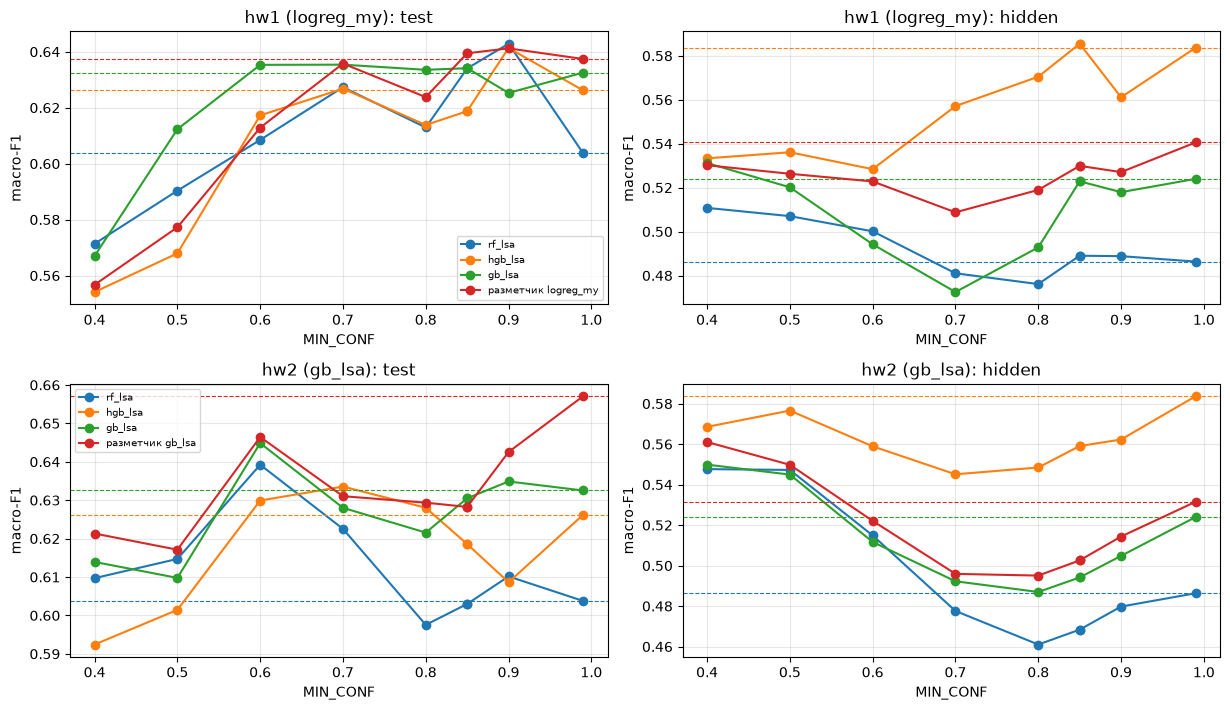

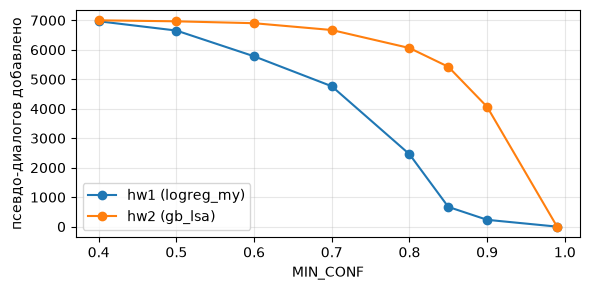

In [19]:
label = lambda n, k: n if n != "labeler" else f"разметчик {LABELERS[k][0]}"
splits = list(EVAL)
fig, axes = plt.subplots(len(LABELERS), len(splits), figsize=(6.2 * len(splits), 3.6 * len(LABELERS)), squeeze=False)
for i, k in enumerate(LABELERS):
    for j, split in enumerate(splits):
        ax = axes[i][j]
        for m in [*FIXED, "labeler"]:
            s = res[(res["разметчик"] == k) & (res["набор"] == split) & (res["модель"] == m) & res["MIN_CONF"].notna()].sort_values("MIN_CONF")
            line, = ax.plot(s["MIN_CONF"], s["macro_f1"], marker="o", label=label(m, k))
            b = res[(res["разметчик"] == k) & (res["набор"] == split) & (res["модель"] == m) & res["MIN_CONF"].isna()].macro_f1.iloc[0]
            ax.axhline(b, color=line.get_color(), ls="--", lw=.8)
        ax.set_title(f"{k} ({LABELERS[k][0]}): {split}"); ax.set_xlabel("MIN_CONF"); ax.set_ylabel("macro-F1"); ax.grid(alpha=.3)
        if j == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 3))
for k in LABELERS:
    plt.plot(n_pseudo[k].index, n_pseudo[k].values, marker="o", label=f"{k} ({LABELERS[k][0]})")
plt.xlabel("MIN_CONF"); plt.ylabel("псевдо-диалогов добавлено"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

## 5. Лучшие пороги и сравнение моделей на `test` 

In [20]:
best_conf = {k: float(grid_score.loc[k]["test"].idxmax()) for k in LABELERS}
for k, t in best_conf.items():
    line = f"{k} ({LABELERS[k][0]}): наилучший MIN_CONF = {t} (деревья на test {grid_score.loc[(k, t), 'test']:.3f}, без псевдо {base_score[(k, 'test')]:.3f})"
    if "hidden" in grid_score.columns:
        th = float(grid_score.loc[k]["hidden"].idxmax())
        line += f"; на hidden {grid_score.loc[(k, t), 'hidden']:.3f} (без псевдо {base_score[(k, 'hidden')]:.3f}), лучший по hidden — {th}"
    print(line)
best_labeler = max(LABELERS, key=lambda k: grid_score.loc[(k, best_conf[k]), "test"])
print(f"\nлучшая связка по test: разметчик {best_labeler} ({LABELERS[best_labeler][0]}), MIN_CONF = {best_conf[best_labeler]}")
if all(grid_score.loc[(k, best_conf[k]), "test"] <= base_score[(k, "test")] for k in LABELERS):
    print("ВНИМАНИЕ: ни один порог не лучше варианта без псевдо-разметки — на этих данных самоподпись не помогает")


def collect():
    """Все модели для сравнения: без псевдо-разметки (A) и обученные на расширенной выборке при лучшем пороге каждого разметчика."""
    out = {f"{n} | A: без псевдо": m for n, m in baseline["hw1"].items() if n != "labeler"}
    for k, (name, _) in LABELERS.items():
        out[f"{name} (разметчик {k}) | A: без псевдо"] = baseline[k]["labeler"]
        for n, m in models_by[(k, best_conf[k])].items():
            out[f"{f'{name} (разметчик {k})' if n == 'labeler' else n} | дообучен разметчиком {k}, MIN_CONF={best_conf[k]}"] = m
    return out


compared = collect()
test_cmp = pd.DataFrame(evaluate(compared, splits=["test"])).drop(columns="набор").sort_values("macro_f1", ascending=False).round(3)
test_cmp.to_csv("results/selftrain_test.csv", index=False)
su.show_table(test_cmp[["модель", "macro_f1", "macro_f1_bal", "accuracy", "balanced_acc", "R_negative", "R_neutral", "R_positive", "F1_positive"]])

hw1 (logreg_my): наилучший MIN_CONF = 0.9 (деревья на test 0.636, без псевдо 0.621); на hidden 0.523 (без псевдо 0.531), лучший по hidden — 0.85
hw2 (gb_lsa): наилучший MIN_CONF = 0.6 (деревья на test 0.638, без псевдо 0.621); на hidden 0.528 (без псевдо 0.531), лучший по hidden — 0.5

лучшая связка по test: разметчик hw2 (gb_lsa), MIN_CONF = 0.6


,модель,macro_f1,macro_f1_bal,accuracy,balanced_acc,R_negative,R_neutral,R_positive,F1_positive
8,gb_lsa (разметчик hw2) | A: без псевдо,0.657,0.609,0.748,0.620,0.578,0.899,0.383,0.505
12,"gb_lsa (разметчик hw2) | дообучен разметчиком hw2, MIN_CONF=0.6",0.646,0.622,0.718,0.626,0.632,0.811,0.433,0.515
11,"gb_lsa | дообучен разметчиком hw2, MIN_CONF=0.6",0.645,0.619,0.715,0.623,0.627,0.808,0.433,0.520
4,"rf_lsa | дообучен разметчиком hw1, MIN_CONF=0.9",0.643,0.584,0.740,0.599,0.562,0.901,0.333,0.488
5,"hgb_lsa | дообучен разметчиком hw1, MIN_CONF=0.9",0.641,0.645,0.708,0.645,0.589,0.797,0.550,0.520
7,"logreg_my (разметчик hw1) | дообучен разметчиком hw1, MIN_CONF=0.9",0.641,0.599,0.723,0.609,0.595,0.848,0.383,0.505
9,"rf_lsa | дообучен разметчиком hw2, MIN_CONF=0.6",0.639,0.618,0.708,0.621,0.638,0.792,0.433,0.510
3,logreg_my (разметчик hw1) | A: без псевдо,0.637,0.605,0.715,0.612,0.616,0.820,0.400,0.500
2,gb_lsa | A: без псевдо,0.633,0.587,0.728,0.599,0.546,0.885,0.367,0.478
10,"hgb_lsa | дообучен разметчиком hw2, MIN_CONF=0.6",0.630,0.643,0.690,0.642,0.632,0.744,0.550,0.508


### Псевдо-разметка при лучших порогах

In [22]:
for k in LABELERS:
    extended = extended_by[(k, best_conf[k])]
    pseudo = extended[extended.pseudo]
    pseudo[["dialog_id", "reaction", "conf", "round"]].to_csv(f"results/pseudo_labels_{k}.csv", index=False)
    logs[(k, best_conf[k])].round(3).to_csv(f"results/selftrain_log_{k}.csv", index=False)
    print(f"--- {k}: {len(pseudo)} диалогов; классы (настоящая разметка / псевдо):")
    print(pd.DataFrame({"train": train.reaction.value_counts(normalize=True), "псевдо": pseudo.reaction.value_counts(normalize=True)}).round(3).T.to_string())
logs[(best_labeler, best_conf[best_labeler])].round(3)

--- hw1: 231 диалогов; классы (настоящая разметка / псевдо):
reaction  negative  neutral  positive
train        0.308    0.591     0.101
псевдо       0.623      NaN     0.377
--- hw2: 6902 диалогов; классы (настоящая разметка / псевдо):
reaction  neutral  negative  positive
train       0.591     0.308     0.101
псевдо      0.602     0.315     0.083


,раунд,размечено,из них псевдо,в пуле,сохраняем,мин. уверенность,+negative,+neutral,+positive
0,1,2400,0,7000,450,0.687,150,150,150
1,2,2850,450,6550,393,0.600,150,150,93
2,3,3243,843,6157,373,0.600,150,150,73
3,4,3616,1216,5784,349,0.602,150,150,49
4,5,3965,1565,5435,335,0.611,150,150,35
5,6,4300,1900,5100,324,0.602,150,150,24
6,7,4624,2224,4776,327,0.601,150,150,27
7,8,4951,2551,4449,322,0.602,150,150,22
8,9,5273,2873,4127,318,0.601,150,150,18
9,10,5591,3191,3809,318,0.604,150,150,18


## 6. Все модели на `hidden_test`

In [28]:
if "hidden" not in EVAL:
    print(f"{HIDDEN_PATH} не найден: положите файл рядом с ноутбуком или задайте HW2_HIDDEN")
else:
    everything = {**{f"{n} (из artifacts)": m for n, m in reaction_models.items()}, **{n: m for n, m in compared.items()}}
    hidden_cmp = pd.DataFrame(evaluate(everything, splits=["hidden"])).drop(columns="набор").sort_values("macro_f1", ascending=False).round(3)
    hidden_cmp.to_csv("results/selftrain_hidden_all.csv", index=False)
    print("лучшая на hidden:", hidden_cmp.iloc[0]["модель"], hidden_cmp.iloc[0]["macro_f1"])
su.show_table(hidden_cmp)

лучшая на hidden: hw2_stack_all_lr (из artifacts) 0.594


,модель,macro_f1,macro_f1_bal,accuracy,balanced_acc,P_negative,R_negative,F1_negative,P_neutral,R_neutral,F1_neutral,P_positive,R_positive,F1_positive
11,hw2_stack_all_lr (из artifacts),0.594,0.594,0.591,0.591,0.509,0.576,0.541,0.555,0.539,0.547,0.733,0.658,0.693
14,hgb_lsa | A: без псевдо,0.584,0.584,0.579,0.579,0.517,0.600,0.555,0.513,0.597,0.552,0.798,0.539,0.644
8,hw2_hgb_lsa (из artifacts),0.566,0.566,0.562,0.562,0.495,0.570,0.530,0.499,0.618,0.552,0.816,0.497,0.618
9,hw2_rf_lsa (из artifacts),0.566,0.566,0.561,0.561,0.507,0.524,0.516,0.476,0.664,0.554,0.862,0.494,0.628
12,hw2_stack_old_lr (из artifacts),0.563,0.563,0.561,0.561,0.497,0.570,0.531,0.526,0.521,0.524,0.684,0.591,0.634
18,"hgb_lsa | дообучен разметчиком hw1, MIN_CONF=0.9",0.561,0.561,0.558,0.558,0.511,0.576,0.541,0.481,0.639,0.549,0.844,0.458,0.593
23,"hgb_lsa | дообучен разметчиком hw2, MIN_CONF=0.6",0.559,0.559,0.552,0.552,0.472,0.609,0.532,0.484,0.542,0.511,0.856,0.503,0.634
4,hw1_logreg_my (из artifacts),0.541,0.541,0.542,0.542,0.492,0.588,0.536,0.478,0.664,0.556,0.899,0.376,0.530
16,logreg_my (разметчик hw1) | A: без псевдо,0.541,0.541,0.542,0.542,0.492,0.588,0.536,0.478,0.664,0.556,0.899,0.376,0.530
10,hw2_rf_tfidf (из artifacts),0.534,0.534,0.539,0.539,0.503,0.509,0.506,0.465,0.748,0.574,0.952,0.361,0.523


## 7. Сохранение

In [24]:
OUT = "artifacts/selftrain_models"
os.makedirs(OUT, exist_ok=True)
for k in LABELERS:
    for n, model in models_by[(k, best_conf[k])].items():
        fname = f"reaction_hw2_{n}_selftrain_{k}.joblib" if n != "labeler" else f"reaction_hw2_labeler_{LABELERS[k][0]}_selftrain_{k}.joblib"
        joblib.dump(model, os.path.join(OUT, fname), compress=3)
        print(f"saved: {OUT}/{fname}  (MIN_CONF={best_conf[k]})")

saved: artifacts/selftrain_models/reaction_hw2_rf_lsa_selftrain_hw1.joblib  (MIN_CONF=0.9)
saved: artifacts/selftrain_models/reaction_hw2_hgb_lsa_selftrain_hw1.joblib  (MIN_CONF=0.9)
saved: artifacts/selftrain_models/reaction_hw2_gb_lsa_selftrain_hw1.joblib  (MIN_CONF=0.9)
saved: artifacts/selftrain_models/reaction_hw2_labeler_logreg_my_selftrain_hw1.joblib  (MIN_CONF=0.9)
saved: artifacts/selftrain_models/reaction_hw2_rf_lsa_selftrain_hw2.joblib  (MIN_CONF=0.6)
saved: artifacts/selftrain_models/reaction_hw2_hgb_lsa_selftrain_hw2.joblib  (MIN_CONF=0.6)
saved: artifacts/selftrain_models/reaction_hw2_gb_lsa_selftrain_hw2.joblib  (MIN_CONF=0.6)
saved: artifacts/selftrain_models/reaction_hw2_labeler_gb_lsa_selftrain_hw2.joblib  (MIN_CONF=0.6)
